## Hydrocarbons Prediction

### About the dataset

The use of RDKit will be used concurrently with machine learning in order to model the molecular dynamics of a set of hydrocarbons. The dataset contains a number of fields and in particular, the SMILES representation of the molecules. This will be used to extract further information about the molecules.T the Descriptors packagwill be used e to get the atomic weight and the number of aromatic bonds from a molecule given the SMILES representation. ishe Descriptors packagwill e provies a number of useful molecular properties whi will be n udse itheur mode 
A selected e regressiomodel will be trained n onheew dataset to produce predictive models thawill n teou the boiling point and melting point of a hydrocarbon given its atomic weight and number of aromatic rings.

| Variable      | Description                                                                                                 |
| ------------- | ----------------------------------------------------------------------------------------------------------- |
| Class of hydrocarbon          | Describes the class or type of hydrocarbon.                                                                             |
| IUPAC name          | The systematic chemical name of the molecule.                                                                                         |
| Melting point        | The melting point of the hydrocarbon.                                                                                  |
| Boiling point      | The boiling point of the hydrocarbon.                                                                                          |
| Density     | Density of the hydrocarbon.                                                                                       |
| Flash point   | The lowest temperature at which vapors ignite.                                                                                  |
| Autoignition temp      | Temperature at which the substance will spontaneously ignite.                                                                                  |
| pubchem_id        | Identifier from the PubChem database.                                                                              |
| smiles | The SMILES representation of the molecule.                                                                      |

### Data Preprocessing

In [1]:
# Importing necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors

In [2]:
# Loading hydrocarbons dataset
file_path = r"C:\Users\lenovo\Desktop\J_Notebooks\hydrocarbons.csv"
hydro_df = pd.read_csv(file_path)

In [3]:
# Displaying a few rows to inspect dataset
hydro_df.head()

,Class of hydrocarbon,IUPAC name,Melting point,Boiling point,Density,Flash point,Autoignition temp,pubchem_id,smiles
0,Trimetylalkane,"2,2,4-Trimethylpentane",-107.0,99.0,0.69,NaN,396,10907,CC(C)CC(C)(C)C
1,Triaromatics,Phenanthrene,99.0,338.0,1.18,171,>450,995,C1=CC=C2C(=C1)C=CC3=CC=CC=C32
2,Triaromatics,Anthracene,216.0,341.0,1.2825,NaN,NaN,8418,C1=CC=C2C=C3C=CC=CC3=CC2=C1
3,Triaromatics,1-methylanthracene,86.0,342.0,1.04799,NaN,NaN,11884,CC1=CC=CC2=CC3=CC=CC=C3C=C12
4,Triaromatics,2-methylanthracene,209.0,340.0,1.8,NaN,NaN,11936,CC1=CC2=CC3=CC=CC=C3C=C2C=C1


#### Converting Smiles to RDKit Molecules and Extracting Properties with Descriptors Package

In [4]:
# Intitialzing empty lists for extarcted properties
atomic_weights = []
aromatic_rings = []

In [5]:
# Extracting properties from each row of the dataframe
for i, row in hydro_df.iterrows():
    smiles = row['smiles']
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        atomic_weight = Descriptors.MolWt(mol)
        num_aromatic_rings = Descriptors.NumAromaticRings(mol)
    else:
        atomic_weight = None
        num_aromatic_rings = None
    atomic_weights.append(atomic_weight)
    aromatic_rings.append(num_aromatic_rings)

In [6]:
# Adding extracted properties to original dataframe
hydro_df['Atomic Weight'] = atomic_weights
hydro_df['Aromatic Rings'] = aromatic_rings

The above process loops through each molecule’s SMILES representation, by using the **'Chem.MolFromSmiles()'** function to convert the SMILES string to an RDKit molecule and extracts the atomic weight and the number of aromatic rings using RDKit's Descriptors.
A failsafe measure is put in place in case the SMILES fails to convert to a molecule. This is done by setting the values to **None**.

In [7]:
# Displaying the updated dataframe
hydro_df.head()

,Class of hydrocarbon,IUPAC name,Melting point,Boiling point,Density,Flash point,Autoignition temp,pubchem_id,smiles,Atomic Weight,Aromatic Rings
0,Trimetylalkane,"2,2,4-Trimethylpentane",-107.0,99.0,0.69,NaN,396,10907,CC(C)CC(C)(C)C,114.232,0
1,Triaromatics,Phenanthrene,99.0,338.0,1.18,171,>450,995,C1=CC=C2C(=C1)C=CC3=CC=CC=C32,178.234,3
2,Triaromatics,Anthracene,216.0,341.0,1.2825,NaN,NaN,8418,C1=CC=C2C=C3C=CC=CC3=CC2=C1,178.234,3
3,Triaromatics,1-methylanthracene,86.0,342.0,1.04799,NaN,NaN,11884,CC1=CC=CC2=CC3=CC=CC=C3C=C12,192.261,3
4,Triaromatics,2-methylanthracene,209.0,340.0,1.8,NaN,NaN,11936,CC1=CC2=CC3=CC=CC=C3C=C2C=C1,192.261,3


In [8]:
# Creating new dataset for regression modeling and displaying it
model_df = hydro_df[['Atomic Weight', 'Aromatic Rings', 'Melting point', 'Boiling point']]
model_df

,Atomic Weight,Aromatic Rings,Melting point,Boiling point
0,114.232,0,-107.0,99.0
1,178.234,3,99.0,338.0
2,178.234,3,216.0,341.0
3,192.261,3,86.0,342.0
4,192.261,3,209.0,340.0
...,...,...,...,...
189,224.432,0,4.0,285.0
190,238.459,0,11.0,301.0
191,252.486,0,18.0,316.0
192,266.513,0,23.0,331.0


In [9]:
# Identifying missing values within the new dataframe
hydro_df.isnull().sum()

Class of hydrocarbon      0
IUPAC name                0
Melting point             6
Boiling point             4
Density                   5
Flash point             117
Autoignition temp       131
pubchem_id                0
smiles                    0
Atomic Weight             0
Aromatic Rings            0
dtype: int64

In the new dataset, we observed that the main features to be used to build the predictive model contain missing values. To remedy this situation, removing the missing values, for the **Melting point** and **Boiling point**, is the ideal course of action. This aims to improve data quality, enhance model performance by improving accuracy and reliability of the model and data analysis.

In [10]:
# Dropping rows with missing values
model_cleaned = model_df.dropna()
model_cleaned.head()

,Atomic Weight,Aromatic Rings,Melting point,Boiling point
0,114.232,0,-107.0,99.0
1,178.234,3,99.0,338.0
2,178.234,3,216.0,341.0
3,192.261,3,86.0,342.0
4,192.261,3,209.0,340.0


### Model Selection and Evaluation

In [11]:
# Installing missing modules
!pip install -U scikit-learn

In [12]:
# Importing necessary libraries for modeling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [13]:
# Feature and Target selection for Melting and Boiling Points
X = model_cleaned[['Atomic Weight', 'Aromatic Rings']]
y_melting = model_cleaned['Melting point']
y_boiling = model_cleaned['Boiling point']

In [14]:
# Splitting dataset into training and testing sets
X_train, X_test, y_melting_train, y_melting_test = train_test_split(X, y_melting, test_size=0.2, random_state=1)
_, _, y_boiling_train, y_boiling_test = train_test_split(X, y_boiling, test_size=0.2, random_state=1)

Linear Regression Model is the starting point for this regression task because it is assumed that the relationship between the features (like atomic weight and aromatic rings) and the target variables (melting and boiling points) are linear. However, this may not be the best model depending on different characteristics and simply that other Regression models may perform much better due to nuances in the data.

In [15]:
# Initializing and training melting point regression model
melting_model = LinearRegression()
melting_model.fit(X_train, y_melting_train)

LinearRegression()

In [16]:
# Initializing and training boiling point regression model
boiling_model = LinearRegression()
boiling_model.fit(X_train, y_boiling_train)

LinearRegression()

In [17]:
# Predicting melting points
melting_pred = melting_model.predict(X_test)

In [18]:
# Predicting boiling points
boiling_pred = boiling_model.predict(X_test)

In [19]:
# Evaluating the models
melting_mse = mean_squared_error(y_melting_test, melting_pred)
boiling_mse = mean_squared_error(y_boiling_test, boiling_pred)
melting_r2 = r2_score(y_melting_test, melting_pred)
boiling_r2 = r2_score(y_boiling_test, boiling_pred)

In [20]:
# Displaying evaluation metrics
print('Melting Point Model:')
print('MSE:', melting_mse)
print('R2:', melting_r2)
print()
print('Boiling Point Model:')
print('MSE:', boiling_mse)
print('R2:', boiling_r2)

Melting Point Model:
MSE: 2425.7839263998053
R2: 0.5718131752277189

Boiling Point Model:
MSE: 2444.5534250221303
R2: 0.8746943970671008


For comparison, the Polynomial Regression Model is trained by extending the Linear Regression, which involves adding polynomial features to capture all possible nonlinear relationships in the data.
If the result of the polynomial regression model is lower MSE and higher R2 values compared to the linear model, then it is assumed that the relationships in the data might be non-linear. This suggests that the polynomial regression is a better fit.

In [21]:
# Importing libraries for Polynomial Regression
from sklearn.preprocessing import PolynomialFeatures
import numpy as np

In [22]:
# Generating polynomial features
degree = 3
poly = PolynomialFeatures(degree=degree, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [23]:
# Initializing and Training Polynomial Melting Model
poly_melting_model = LinearRegression()
poly_melting_model.fit(X_train_poly, y_melting_train)

LinearRegression()

In [24]:
# Initializing and Training Polynomial Boiling Model
poly_boiling_model = LinearRegression()
poly_boiling_model.fit(X_train_poly, y_boiling_train)

LinearRegression()

In [25]:
# Prediction on Polynomial Melting Model
melting_poly_pred = poly_melting_model.predict(X_test_poly)

In [26]:
# Prediction on Polynomial Boiling Model
boiling_poly_pred = poly_boiling_model.predict(X_test_poly)

In [27]:
# Evaluating Polynomial Regression Models
melting_poly_mse = mean_squared_error(y_melting_test, melting_poly_pred)
boiling_poly_mse = mean_squared_error(y_boiling_test, boiling_poly_pred)
melting_poly_r2 = r2_score(y_melting_test, melting_poly_pred)
boiling_poly_r2 = r2_score(y_boiling_test, boiling_poly_pred)

In [28]:
# Displaying Evaluation Metrics
print('Polynomial Melting Point Model (degree=', degree,'):')
print('MSE:', melting_poly_mse)
print('R2:', melting_poly_r2)
print()
print('Polynomial Boiling Point Model (degree=', degree,'):')
print('MSE:', boiling_poly_mse)
print('R2:', boiling_poly_r2)

Polynomial Melting Point Model (degree= 3 ):
MSE: 1887.969925219046
R2: 0.6667453194213856

Polynomial Boiling Point Model (degree= 3 ):
MSE: 278.1850862886925
R2: 0.9857404834733651


Based on the metrics obtained above, the Polynomial Regression model at the 3rd degree, outperformed the Linear Regression model for both the melting point and boiling point predictions.
The Polynomial Regression model has a lower Mean Squared Error (MSE):'1887.97' and a higher R2 value (0.67) compared to the Linear Regression model with MSE (2425.78) and R2 (0.57), suggesting that the relationship between the features and the melting point is captured better. This is similar for the Boiling point, with the Polynomial Regression model values at 278.19(MSE) and 0.98(R2) compared to 2444.55(MSE) and 0.87(R2).

The Polynomial Regression model performed better for both tasks, with lower MSE values suggesting less error in predictions and higher R2 values suggesting a better fit to the data. From this evaluation, it is observed that the relationship between the features (**atomic weight and aromatic rings**) and the target variables (**melting and boiling points**) is likely non-linear. The polynomial regression model captures the non-linearity better than linear regression model, making it the better choice for this dataset.

Scatter plots will be created to visualize the performance of the Polynomial Regression models. The actual vs predicted values will be plotted for both the melting point and boiling point models.

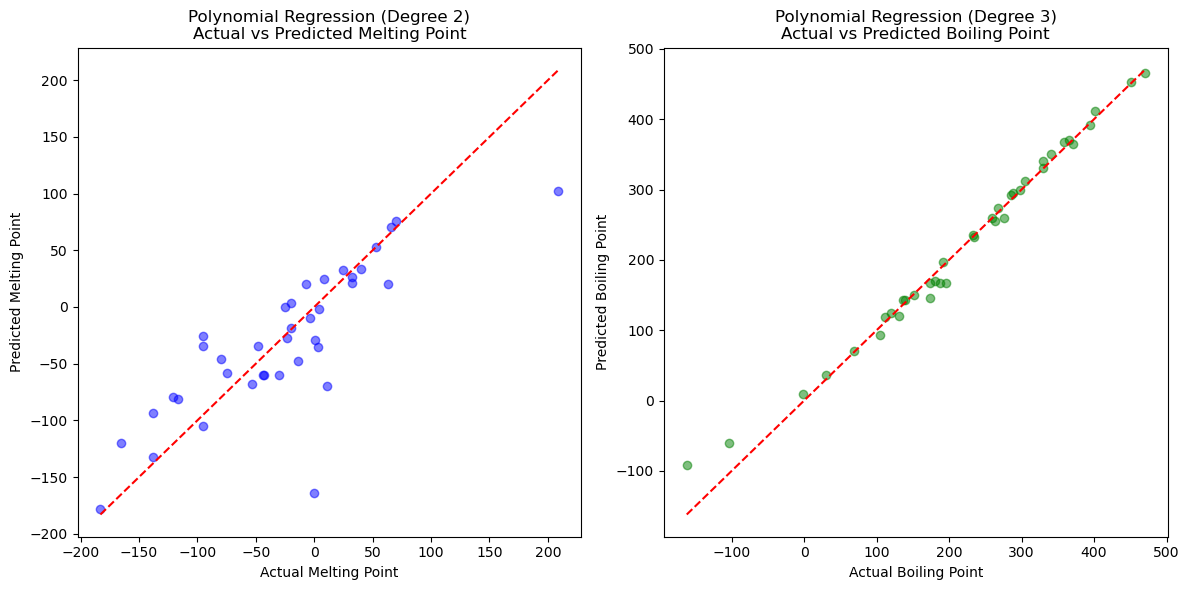

In [34]:
# Plotting Polynomial Regression model
plt.figure(figsize=(12, 6))

# Plotting actual vs predicted values for melting point
plt.subplot(1, 2, 1)
plt.scatter(y_melting_test, melting_poly_pred, color='blue', alpha=0.5)
plt.plot([min(y_melting_test), max(y_melting_test)], [min(y_melting_test), max(y_melting_test)], color='red', linestyle='--')
plt.xlabel('Actual Melting Point')
plt.ylabel('Predicted Melting Point')
plt.title('Polynomial Regression (Degree 2)\nActual vs Predicted Melting Point')

# Plotting actual vs predicted values for boiling point
plt.subplot(1, 2, 2)
plt.scatter(y_boiling_test, boiling_poly_pred, color='green', alpha=0.5)
plt.plot([min(y_boiling_test), max(y_boiling_test)], [min(y_boiling_test), max(y_boiling_test)], color='red', linestyle='--')
plt.xlabel('Actual Boiling Point')
plt.ylabel('Predicted Boiling Point')
plt.title('Polynomial Regression (Degree 3)\nActual vs Predicted Boiling Point')

# Displaying the plots
plt.tight_layout()
plt.show()

The above plots show the scatter plots for both the melting and boiling points. 
The scatter points for the **boiling point** are tightly clustered around the diagonal line, indicating that the Polynomial Regression model is making accurate predictions. The **melting point** scatter plot on the other hand does not have the scatter point tightly clustered but rather more spread out. These deviations from the line show the areas where the model failed to predict accurately. These predictions differ from the actual values.
The **melting point** model has better prediction abilities, while the **boiling point** model has less prediction abilities.